# 双通道 FRET 批量处理

对一组 sif **共用同一份配准文件**（`CALIBRATION_FILE`），逐视野跑完整流程并落盘。
取框、漂移、emitter、trace、判据、E 的口径**全部与 `smTest_dual.ipynb` 一致** ——
改参数只需要改下面那个配置格。

每个视野的成品写在 `<sif 同目录>/<sif 主名>_fret{OUT_TAG}/`：

| 文件 | 内容 |
|---|---|
| `fret.csv` | 逐分子 E 与 γ/α/β，**外加判据量** `red_label` / `red_duty` / `spread` / `n_d_pre`；只取 `red_label == "steady"` 就是"受体平稳"的子集 —— 下游统计只读它 |
| `E_distribution.png` | E 分布 + E vs 受体亮度 + E vs $I_D^{pre}$ |
| `good_traces_all.png` | 通过判据的 trace 全览 |
| `traces_all.csv` | 全部 trace（一行 = 一分子一帧），`fr.load_traces_csv` 可读回；`SAVE_ALL_TRACES=False` 时不写 |
| `good_traces.csv` | 通过判据的那些 trace（同格式） |

整批的汇总写在 `SUMMARY_DIR`（默认第一个 sif 同目录下的 `FRET_summary/`）：
`fret_summary.csv`（逐视野计数与 E 统计）+ `E_all_fields.png`（所有视野池化的 E）。


In [ ]:
# `import smlm` 需要 Py_Smile 在 sys.path 上; notebook 放进子目录后自己找一下
import pathlib
import sys

for _q in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_q / 'smlm' / '__init__.py').is_file():
        sys.path.insert(0, str(_q))
        break


In [1]:
%load_ext autoreload
%autoreload 2

In [13]:
import gc
import time
import traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import smlm.fret as fr
import smlm.multiplex as mp
from smlm.camera import EMCCD
from smlm.imgprocess import Crop, Pipeline, SelectFrames
from smlm.io import load_raw
from smlm.localize import localize_stack

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ======================= 输入 =======================
# 一份标定, 全部视野共用
CALIBRATION_FILE = Path(
    r"G:\PacBio\近观DNA_FRET\20261109\std2_multichannel_calibration.npz")

SIF_FILES = [
    r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov1.sif",
    r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov2.sif",
    r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov3.sif",
    r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov4.sif",
    r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov5.sif",
    r"G:\PacBio\近观DNA_FRET\20261123\sample32_532nm_2mW_0p1S_2000frames_fov6.sif",
]
SIF_FILES = [
    r"G:\PacBio\近观DNA_FRET\20261109\sample1_532nm_2mW_0p1S_2000frames_fov5.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample1_532nm_2mW_0p1S_2000frames_fov6.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample2_532nm_2mW_0p1S_2000frames_fov1.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample2_532nm_2mW_0p1S_2000frames_fov2.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample2_532nm_2mW_0p1S_2000frames_fov3.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample4_532nm_2mW_0p1S_2000frames_fov2.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample4_532nm_2mW_0p1S_2000frames_fov3.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample5_532nm_2mW_0p1S_2000frames_fov1.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample5_532nm_2mW_0p1S_2000frames_fov2.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample5_532nm_2mW_0p1S_2000frames_fov3.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample6_532nm_2mW_0p1S_2000frames_fov1.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample6_532nm_2mW_0p1S_2000frames_fov2.sif",
    r"G:\PacBio\近观DNA_FRET\20261109\sample6_532nm_2mW_0p1S_2000frames_fov3.sif",
]
SIF_FILES = [Path(p) for p in SIF_FILES]

# 只补算个别视野时填文件名子串, 例如 ['fov5', 'sample2']; 空 = 全部
ONLY_FILES = []

# ======================= 输出去向 =======================
OUT_TAG = ''            # 想保住上一轮就改成 '_g1p1'
# 连"未筛选"的 traces_all.csv 一起写 (一个 760 分子 x 2000 帧的视野约 76 MB);
# 只要合格分子就设 False
SAVE_ALL_TRACES = True
# 汇总放哪; None = 第一个 sif 同目录下的 FRET_summary/
SUMMARY_DIR = None

# ======================= 相机 / 裁切 (同 smTest_dual) =======================
CAM_KW = dict(conv_factor=5.75, em_gain=300)
PIXEL_SIZE_NM = 106.6
CROP_Y, CROP_X = (0, 512), (0, 512)     # 先裁到 512x512
FRAME_STOP = 2000                       # None = 全部帧
TRIM_TOP, TRIM_BOTTOM = 50, 50          # 标定 ROI 之内再收边
TRIM_LEFT, TRIM_RIGHT = 0, 0
SHOW_ROI = False                        # 批量时不弹取框图

# ======================= 定位 =======================
READ_LOC_CACHE = False                  # False = 重算并覆盖缓存; True = 只读缓存(缺了报错)
LOC_CACHE_SUBDIR = 'localization_cache'
K_SIGMA = {'g': 2.0, 'r': 1.4}
DET_KW = dict(edge=5, f_em=np.sqrt(2), bg_window=15,
              max_size=7, min_neighbors=2)
LOC_KW = dict(edge=5, F_EM=np.sqrt(2), use_pixel=False,
              use_gradient=True, n_jobs=14, verbose=False)
FILT_KW = dict(photons=(3, 1e7), bg=(0, 1e5), sigma=(0.7, 4.0), lp=None)

# ======================= 漂移 =======================
FRAMES_PER_SEG = 10
DRIFT_UNCERTAINTY_PX = None             # None = 用定位精度 lp 的中位数
DRIFT_PAD_PX = dict(top=4, bottom=4, left=4, right=4)
EDGE_TRIM_PX = dict(top=7, bottom=7, left=7, right=7)
LOC_EDGE = 5
DRIFT_INTERPOLATION_ORDER = 1

# ======================= emitter / trace =======================
LINK_KW = dict(search_radius=0.6, max_gap=1000, motion='static',
               ecc_p=1e-3)              # first_frame_range 逐视野补
LINK_KW_BY_CHANNEL = {
    'g': dict(search_radius=0.9, min_frames=5, ecc_min=None, do_merge=False),
    'r': dict(min_frames=5, ecc_min=1.5, do_merge=True),
}
# 取 trace 的 σ 用**逐通道的拟合宽度中位** (见 process_one 第 6 步);
# 这里的理论值只打印出来做对照, 不参与计算
WAVELEN_NM, NA = 640.0, 1.4
TRACE_CENTERS_FROM = {'r': 'r', 'g': 'r'}   # 孔径中心一律来自红通道
TRACE_MASK_FROM = {'r': 'r', 'g': 'g'}      # 背景环用各自通道的 emitter 挖洞
TRACE_MODE, TRACE_K_SIGMA = 'matched', 2.0

# ======================= 判据 / 效率 =======================
PAIR_CRIT = fr.PairCriteria(
    red_min=80.0,      # 台阶前 red_win 帧的中位亮度必须高于它
    red_win=10,
    lag_max=10,         # 绿光去淬灭允许滞后 (帧)
    pre_win=60,         # "洁净度"检查窗 (帧), 只统计受体亮着的帧
    k_spread=2.5,       # pre 窗离散度 <= 2.5 x 光子噪声
    pre_duty_win=150,   # 受体 ON 占空比的统计窗 (帧)
    red_duty_min=0.5,   # 台阶前 ON 占比下限: 更低 = 只是一次闪光的结束
    blink_relax=2.0,    # 受体在闪时, 灭后占空比上限放宽这么多倍
    attr_scale=0.8,     # 归属半径 = 0.8 x 孔径半径
    attr_dup=0.9,       # 相距 < 0.9 px 的绿光中心算同一个物理分子
    max_n_pre=1,        # pre 窗内孔径里最多 1 个绿光分子
)
GAMMA_FIXED = 1.1       # 通道增益比固定; 逐视野估计值只记录不采用
# α (供体串扰) / β (受体通道加性偏移) 同样全批固定: 每个视野只有 ~10 条合格事件,
# 逐视野估会让同一样品在 6 个不同校正基线上算 E (实测 α 在 0.068~0.264 之间飘,
# fov5 就因此出一条 E=-0.148)。这组值由 64 条分子的"灭后残留"联合拟合
# I_A^post = α·I_D^post + β 得到, 逐视野估计值仍写进汇总表做对照。
ALPHA_FIXED = 0.096
BETA_FIXED = 6.3

# ======================= 校验 =======================
if not CALIBRATION_FILE.is_file():
    raise FileNotFoundError(CALIBRATION_FILE)
missing = [str(p) for p in SIF_FILES if not p.is_file()]
if missing:
    raise FileNotFoundError('缺少 sif:\n  ' + '\n  '.join(missing))
if SUMMARY_DIR is None:
    SUMMARY_DIR = SIF_FILES[0].parent / 'FRET_summary'
SUMMARY_DIR = Path(SUMMARY_DIR)

TODO = [p for p in SIF_FILES
        if not ONLY_FILES or any(k in p.name for k in ONLY_FILES)]
print(f'标定 : {CALIBRATION_FILE.name}')
print(f'视野 : {len(TODO)} / {len(SIF_FILES)} 个   '
      f'(γ 固定 {GAMMA_FIXED}, 裁切 {CROP_Y}/{CROP_X}, trim {TRIM_TOP}/{TRIM_BOTTOM})')
print(f'汇总 : {SUMMARY_DIR}')


标定 : std2_multichannel_calibration.npz
视野 : 13 / 13 个   (γ 固定 1.1, 裁切 (0, 512)/(0, 512), trim 50/50)
汇总 : G:\PacBio\近观DNA_FRET\20261109\FRET_summary


In [14]:
_T0 = 0.0


def _p(msg):
    """带耗时戳的进度行 (相对当前视野开始)。"""
    print(f'  {time.time() - _T0:6.1f}s  {msg}', flush=True)


def process_one(src, *, verbose=True):
    """跑一个 sif, 成品写进 <sif 同目录>/<主名>_fret{OUT_TAG}/。

    Returns
    -------
    (row, results) : (dict, list[FretResult])
        ``row`` 是汇总表的一行; ``results`` 留给整批池化用。
    """
    global _T0
    _T0 = time.time()
    src = Path(src)
    out_dir = src.with_suffix('').with_name(src.stem + '_fret' + OUT_TAG)

    # ---- 1) 读 sif -> 光子 -> 裁切 (与 smTest_dual 完全相同) ----
    raw = load_raw(src)
    raw.metadata.pop('imageData', None)
    ex_time = float(raw.exposure_time)
    image = EMCCD(**CAM_KW).process(raw, pixel_size=PIXEL_SIZE_NM)
    del raw

    h, w = image.shape[-2:]
    crop_y = (CROP_Y[0], min(CROP_Y[1], h))
    crop_x = (CROP_X[0], min(CROP_X[1], w))
    if crop_y != tuple(CROP_Y) or crop_x != tuple(CROP_X):
        _p(f'[!] 图像只有 {h}x{w}, 裁切被夹到 y{crop_y} x{crop_x}')
    stack = Pipeline(Crop(y=crop_y, x=crop_x),
                     SelectFrames(start=0, stop=FRAME_STOP))(image)
    del image
    _p(f'读入 : {stack.n_frames} 帧  {ex_time * 1000:.0f} ms/帧  '
       f'{stack.shape[1:]}')

    # ---- 2) 按配准文件取框, 再在标定 ROI 内收边 ----
    multi = mp.multichannel_stack_from_calibration(
        stack, CALIBRATION_FILE, show_roi=SHOW_ROI)
    del stack
    _, _, multi_h, multi_w = multi.shape
    analysis_y = (TRIM_TOP, multi_h - TRIM_BOTTOM)
    analysis_x = (TRIM_LEFT, multi_w - TRIM_RIGHT)
    if analysis_y[1] <= analysis_y[0] or analysis_x[1] <= analysis_x[0]:
        raise ValueError(f'收边后窗口为空: y={analysis_y} x={analysis_x}')
    multi_analysis = multi.crop(y=analysis_y, x=analysis_x)
    del multi
    _p(f'取框 : y{analysis_y} x{analysis_x}  '
       f'通道 {list(multi_analysis.channels)}  参考 {multi_analysis.ref_name!r}')

    # ---- 3) 双通道定位 (带缓存) ----
    cache_dir = src.parent / LOC_CACHE_SUBDIR
    cache_dir.mkdir(parents=True, exist_ok=True)
    multi_locs = {}
    for channel in multi_analysis.channels:
        multi_locs[channel] = localize_stack(
            multi_analysis.channel(channel),
            k_sigma=K_SIGMA.get(channel, 1.5),
            det_kw=DET_KW, loc_kw=LOC_KW, filt_kw=FILT_KW,
            src_path=cache_dir / f'{src.stem}_{channel}',
            read_cache=READ_LOC_CACHE, verbose=False, tag=channel)
    _p('定位 : ' + '  '.join(f'{c}={len(v)}' for c, v in multi_locs.items()))

    # ---- 4) 漂移: 合并点云估一条 -> 换算到各通道 -> 同尺寸裁切 ----
    drift = mp.estimate_drift_multi(
        multi_analysis, multi_locs,
        drift_reference=multi_analysis.ref_name,
        estimate_channels=tuple(multi_analysis.channels),
        frames_per_seg=FRAMES_PER_SEG,
        uncertainty_px=DRIFT_UNCERTAINTY_PX, verbose=False)
    window = mp.drift_crop_window(
        drift, multi_analysis.shape[-2:],
        pad=DRIFT_PAD_PX, extra_trim=EDGE_TRIM_PX)
    multi_corr, locs_corr = mp.correct_multi(
        multi_analysis, multi_locs, drift, window=window,
        edge=LOC_EDGE, interpolation_order=DRIFT_INTERPOLATION_ORDER,
        verbose=False)
    corr_y, corr_x = (int(v) for v in multi_corr.shape[-2:])
    del multi_analysis, multi_locs
    _p('漂移 : ' + '  '.join(f'{c}={drift[c].total_drift:.2f}px'
                             for c in drift)
       + f'  -> {multi_corr.shape[-2:]}')

    # ---- 5) emitter ----
    n_frames = int(multi_corr.n_frames)
    emitters, all_emitters = mp.analyze_multichannel_emitters(
        multi_corr, locs_corr, n_frames=n_frames,
        link_kw={**LINK_KW, 'first_frame_range': (0, n_frames - 1)},
        link_kw_per_channel=LINK_KW_BY_CHANNEL,
        return_all=True, verbose=False)
    _p('emitter: ' + '  '.join(
        f'{c}={len(emitters[c])}/{len(all_emitters[c])}' for c in emitters))

    # ---- 6) trace (中心来自红, 背景各自挖洞) ----
    # 逐通道的拟合宽度中位 (理论 0.2165λ/NA 在这批数据上偏小 ~45%)
    sigma_px = mp.psf_sigma_from_locs(locs_corr)
    sigma_theory = 0.2165 * WAVELEN_NM / NA / float(multi_corr.pixel_size)
    traces = mp.extract_multichannel_traces(
        multi_corr, emitters,
        centers_from=TRACE_CENTERS_FROM, mask_from=TRACE_MASK_FROM,
        sigma=sigma_px, mode=TRACE_MODE, k_sigma=TRACE_K_SIGMA,
        n_frames=n_frames, verbose=False)
    del multi_corr, locs_corr
    _p(f'trace : {len(traces["r"])} 条 (σ='
       + ' '.join(f'{c}={v:.2f}px' for c, v in sigma_px.items())
       + f', 理论 {sigma_theory:.2f}px, 半径 {traces["r"][0]["radius"]}px)')

    # ---- 7) 判据筛选 ----
    records, stats = fr.select_pairs(
        traces['r'], traces['g'], emitters_d=emitters['g'],
        crit=PAIR_CRIT, verbose=False)
    events = [r.event for r in records if r.keep]
    n_duty = sum(1 for r in records if 'duty' in r.reasons)
    lbl = {k: sum(1 for r in records if r.red_label == k)
           for k in ('steady', 'blinking', 'dark', 'unbleached', 'unknown')}
    _p(f'筛选 : {len(records)} 对 -> 合格 {len(events)}   '
       f'(duty 挡 {n_duty}; 红光 '
       + ' '.join(f'{k}={v}' for k, v in lbl.items()) + ')')

    # ---- 8) 标定 + E (γ 固定, α/β 逐视野估) ----
    if events:
        cal = fr.calibrate(events, traces_a=traces['r'],
                           traces_d=traces['g'], verbose=False)
        gamma_est, alpha_est, beta_est = (float(cal.gamma), float(cal.alpha),
                                          float(cal.beta))
    else:
        cal = fr.FretCalibration(gamma=float(GAMMA_FIXED), detail={})
        gamma_est = alpha_est = beta_est = np.nan
    # γ/α/β 一律用全批常量 (逐视野估值只记录): ~10 条事件估不出稳定的 α
    cal.gamma = float(GAMMA_FIXED)
    cal.alpha = float(ALPHA_FIXED)
    cal.beta = float(BETA_FIXED)
    results, _ = fr.fret_efficiency(
        events, traces['r'], traces['g'], cal,
        t_bleach=lambda j: j * ex_time, verbose=False)
    fr.attach_efficiency(records, results)
    _p(f'标定 : γ={cal.gamma:.3f} (估 {gamma_est:.3f})  '
       f'α={cal.alpha:.3f} (估 {alpha_est:.3f})  '
       f'β={cal.beta:+.1f} (估 {beta_est:+.1f})  -> 算出 E {len(results)}')

    # ---- 9) 落盘 ----
    fr.save_bundle(out_dir, records=records, results=results,
                   traces_d=traces['g'], traces_a=traces['r'], cal=cal,
                   ex_time=ex_time, title=src.stem,
                   include_all=SAVE_ALL_TRACES, verbose=False)

    E = np.array([r.E for r in results], float)
    Eok = E[np.isfinite(E)]
    row = dict(
        file=src.name,
        n_frames=n_frames,
        height=corr_y,
        width=corr_x,
        n_emitters_r=len(emitters.get('r', [])),
        n_emitters_g=len(emitters.get('g', [])),
        sigma_r=float(sigma_px.get('r', np.nan)),
        sigma_g=float(sigma_px.get('g', np.nan)),
        sigma_theory=float(sigma_theory),
        radius=int(traces['r'][0]['radius']) if traces.get('r') else -1,
        n_pairs=len(records),
        n_keep=len(events),
        n_duty=n_duty,
        n_blink=sum(1 for r in records if r.red_label == 'blinking'),
        n_E=len(results),
        gamma_est=gamma_est,
        alpha_est=alpha_est,
        beta_est=beta_est,
        gamma_used=float(cal.gamma),
        alpha=float(cal.alpha),
        beta=float(cal.beta),
        E_med=float(np.median(Eok)) if Eok.size else np.nan,
        E_p16=float(np.percentile(Eok, 16)) if Eok.size else np.nan,
        E_p84=float(np.percentile(Eok, 84)) if Eok.size else np.nan,
        n_E_gt1=int((E > 1).sum()),
        seconds=round(time.time() - _T0, 1),
        out_dir=str(out_dir),
        error='',
    )
    _p(f'完成 : E 中位 {row["E_med"]:.3f} (n={row["n_E"]})  -> {out_dir.name}/')
    return row, results


## 汇总

逐视野的计数与 E 统计在 `fret_summary.csv`；把各视野池化后才好判断分布形状
（单个视野的 n 常常只有几十）。失败视野的 `error` 列会写明原因，重跑时把
`ONLY_FILES` 填上对应文件名即可。

表里也记了 `sigma_r` / `sigma_g` / `radius`：σ 是**逐视野实测**的（拟合宽度中位），
`red_min` 这类绝对门限的标度就跟着它走，横向比较视野时要先看同不同量级。
`n_duty` 是被"红光不连续"挡掉的条数，`n_blink` 是受体在闪的分子数。


In [15]:
rows = []
all_results = []

for k, src in enumerate(TODO, 1):
    print(f'\n=== [{k}/{len(TODO)}] {src.name} ' + '=' * max(0, 40 - len(src.name)))
    t_start = time.time()
    try:
        row, results = process_one(src)
        all_results += results
    except Exception as exc:                      # 单个视野失败不拖垮整批
        traceback.print_exc()
        row, results = dict(file=src.name,
                            error=f'{type(exc).__name__}: {exc}',
                            seconds=round(time.time() - t_start, 1)), []
    rows.append(row)
    gc.collect()

summary = pd.DataFrame(rows)
cols = [c for c in ('file', 'n_frames', 'sigma_r', 'sigma_g', 'radius',
                    'n_emitters_r', 'n_emitters_g',
                    'n_pairs', 'n_duty', 'n_blink', 'n_keep', 'n_E',
                    'E_med', 'E_p16', 'E_p84',
                    'n_E_gt1', 'gamma_est', 'alpha_est', 'beta_est',
                    'gamma_used', 'alpha', 'beta', 'seconds', 'error')
        if c in summary.columns]
print('\n' + summary[cols].to_string(index=False,
                                     float_format='{:.3f}'.format))

SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_DIR.joinpath('fret_summary.csv').write_text(
    summary.to_csv(index=False), encoding='utf-8-sig')
print(f'\n汇总表 -> {SUMMARY_DIR / "fret_summary.csv"}')



=== [1/13] sample1_532nm_2mW_0p1S_2000frames_fov5.sif 
     2.8s  读入 : 2000 帧  100 ms/帧  (512, 512)
     3.4s  取框 : y(50, 462) x(0, 236)  通道 ['g', 'r']  参考 'g'
[cache] saved 740241 locs -> G:\PacBio\近观DNA_FRET\20261109\localization_cache\sample1_532nm_2mW_0p1S_2000frames_fov5_g.locs.npz
[cache] saved 250593 locs -> G:\PacBio\近观DNA_FRET\20261109\localization_cache\sample1_532nm_2mW_0p1S_2000frames_fov5_r.locs.npz
   257.3s  定位 : g=740241  r=250593


<string>:12: RuntimeWarning: 分析窗口比标定点覆盖大 26.0 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 26.0 / y 0.0 px


   266.4s  漂移 : g=2.20px  r=2.19px  -> (387, 212)
连接得到 3283 个 emitter
MinDurationFilter: 保留 2739 / 3283
FirstFrameFilter: 保留 2739 / 2739
EccentricityFilter: 保留 998 / 2739
连接得到 8872 个 emitter
合并后剩余 2960 / 8872 个 emitter
MinDurationFilter: 保留 683 / 2960
FirstFrameFilter: 保留 683 / 683
EccentricityFilter: 保留 494 / 683
   290.6s  emitter: g=998/3283  r=494/2960


<string>:12: RuntimeWarning: 分析窗口比标定点覆盖大 14.0 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 14.0 / y 0.0 px


   390.2s  trace : 494 条 (σ=g=1.63px r=1.53px, 理论 0.93px, 半径 4px)
   391.3s  筛选 : 494 对 -> 合格 45   (duty 挡 14; 红光 steady=151 blinking=7 dark=14 unbleached=76 unknown=246)
   391.3s  标定 : γ=1.100 (估 1.523)  α=0.096 (估 0.063)  β=+6.3 (估 -8.5)  -> 算出 E 44
   398.9s  完成 : E 中位 0.998 (n=44)  -> sample1_532nm_2mW_0p1S_2000frames_fov5_fret/

=== [2/13] sample1_532nm_2mW_0p1S_2000frames_fov6.sif 
     5.5s  读入 : 2000 帧  100 ms/帧  (512, 512)
     6.0s  取框 : y(50, 462) x(0, 236)  通道 ['g', 'r']  参考 'g'
[cache] saved 441679 locs -> G:\PacBio\近观DNA_FRET\20261109\localization_cache\sample1_532nm_2mW_0p1S_2000frames_fov6_g.locs.npz
[cache] saved 132360 locs -> G:\PacBio\近观DNA_FRET\20261109\localization_cache\sample1_532nm_2mW_0p1S_2000frames_fov6_r.locs.npz
   155.1s  定位 : g=441679  r=132360
   162.8s  漂移 : g=5.70px  r=5.68px  -> (384, 212)
连接得到 1974 个 emitter
MinDurationFilter: 保留 1576 / 1974
FirstFrameFilter: 保留 1576 / 1576
EccentricityFilter: 保留 661 / 1576
连接得到 7042 个 emitter
合并后剩余 3235 / 7042 个 e

<string>:12: RuntimeWarning: 分析窗口比标定点覆盖大 15.0 px; 当前是 order 1(仿射), 外推精确, 可忽略。   r 超出 x 15.0 / y 0.0 px


   356.3s  trace : 581 条 (σ=g=1.65px r=1.50px, 理论 0.93px, 半径 3px)
   358.1s  筛选 : 581 对 -> 合格 118   (duty 挡 53; 红光 steady=193 blinking=91 dark=53 unbleached=102 unknown=142)
   358.1s  标定 : γ=1.100 (估 1.161)  α=0.096 (估 0.063)  β=+6.3 (估 -5.9)  -> 算出 E 114
   373.7s  完成 : E 中位 0.967 (n=114)  -> sample2_532nm_2mW_0p1S_2000frames_fov1_fret/

=== [4/13] sample2_532nm_2mW_0p1S_2000frames_fov2.sif 
     5.6s  读入 : 2000 帧  100 ms/帧  (512, 512)
     6.1s  取框 : y(50, 462) x(0, 236)  通道 ['g', 'r']  参考 'g'
[cache] saved 441537 locs -> G:\PacBio\近观DNA_FRET\20261109\localization_cache\sample2_532nm_2mW_0p1S_2000frames_fov2_g.locs.npz
[cache] saved 353986 locs -> G:\PacBio\近观DNA_FRET\20261109\localization_cache\sample2_532nm_2mW_0p1S_2000frames_fov2_r.locs.npz
   182.5s  定位 : g=441537  r=353986
   190.7s  漂移 : g=0.98px  r=0.98px  -> (389, 213)
连接得到 5216 个 emitter
MinDurationFilter: 保留 2230 / 5216
FirstFrameFilter: 保留 2230 / 2230
EccentricityFilter: 保留 1326 / 2230
连接得到 10342 个 emitter
合并后剩余 4210 / 1

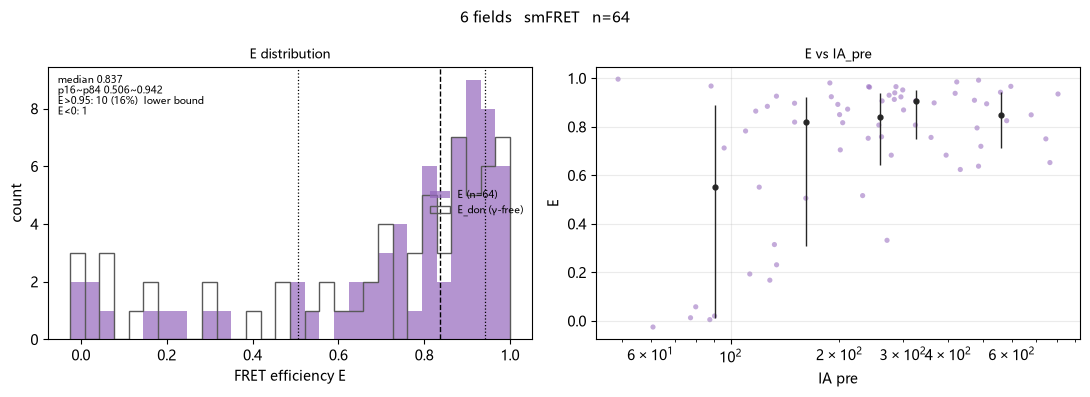

池化图 -> G:\PacBio\近观DNA_FRET\20261123\FRET_summary\E_all_fields.png


In [12]:
# 所有视野池化后的 E 分布 (逐视野的 n 常常只有几十, 池化才看得清形状)
if not all_results:
    print('没有算出 E 的分子')
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    fr.viz.plot_efficiency(all_results, ax=axes[0])
    fr.viz.plot_efficiency_vs_brightness(all_results, ax=axes[1], key='IA_pre')
    fig.suptitle(f'{len(rows)} fields   smFRET   n={len(all_results)}',
                 fontsize=11)
    fig.tight_layout()
    out_png = SUMMARY_DIR / 'E_all_fields.png'
    fig.savefig(out_png, dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'池化图 -> {out_png}')
